# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Integrantes:**

- Andruszyszyn Emanuel
- Quirós Juan

Este notebook sigue las consignas del enunciado (pasos 1 a 20). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
!python -m pytest -q --tb=no -rf

FFFF...........................                                          [100%]
=========================== short test summary info ===========================
FAILED tests/test_derivacion.py::test_derivar - NotImplementedError: Completa...
FAILED tests/test_derivacion.py::test_derivar_umbral_de_fraude_tiene_prioridad
FAILED tests/test_derivacion.py::test_derivar_sin_umbral_de_confianza_deriva_todo
FAILED tests/test_derivacion.py::test_evaluar_derivacion - NotImplementedErro...
4 failed, 27 passed in 2.33s


## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

,Cantidad
Registros,8200
Textos nulos,11
Textos vacíos (incluye nulos y espacios),18
Duplicados por cliente y texto,200


,Tipo de dato,Nulos
id_mensaje,str,0
fecha_hora,str,0
id_cliente,str,0
canal,str,0
texto,str,11
equipo_derivado,str,0
equipo_final,str,0


,Mensajes,Porcentaje
equipo_final,,
transferencias,2552,31.12
tarjeta,2057,25.09
cuenta_acceso,1648,20.10
prestamos_inversiones,1029,12.55
fraude,914,11.15


,Mensajes
canal,
app_chat,3676
whatsapp,2499
email,1163
formulario_web,862


,Mensajes,Promedio,Mediana,Mínimo,Máximo
equipo_final,,,,,
cuenta_acceso,1648,13.87,13.0,0,46
fraude,914,18.22,17.0,0,50
prestamos_inversiones,1029,12.58,12.0,0,33
tarjeta,2057,14.81,14.0,0,42
transferencias,2552,16.95,17.0,0,41


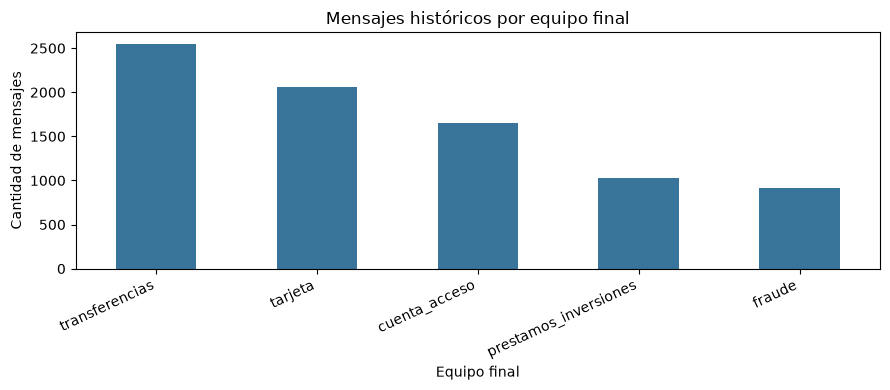

In [3]:
from IPython.display import display

df_original = pd.read_csv("datos/mensajes_historicos.csv")
cantidad_palabras_original = df_original["texto"].fillna("").str.split().str.len()
mensajes_vacios = df_original["texto"].fillna("").str.strip().eq("")
duplicados = df_original.duplicated(subset=["id_cliente", "texto"], keep="first")

resumen_original = pd.Series({
    "Registros": len(df_original),
    "Textos nulos": df_original["texto"].isna().sum(),
    "Textos vacíos (incluye nulos y espacios)": mensajes_vacios.sum(),
    "Duplicados por cliente y texto": duplicados.sum(),
}, name="Cantidad").to_frame()
display(resumen_original)
display(pd.DataFrame({
    "Tipo de dato": df_original.dtypes.astype(str),
    "Nulos": df_original.isna().sum(),
}))

distribucion_equipos = df_original["equipo_final"].value_counts().to_frame("Mensajes")
distribucion_equipos["Porcentaje"] = 100 * distribucion_equipos["Mensajes"] / len(df_original)
display(distribucion_equipos.round(2))
display(df_original["canal"].value_counts().to_frame("Mensajes"))

palabras_por_clase = (
    df_original.assign(palabras=cantidad_palabras_original)
    .groupby("equipo_final")["palabras"]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(columns={"count": "Mensajes", "mean": "Promedio", "median": "Mediana", "min": "Mínimo", "max": "Máximo"})
)
display(palabras_por_clase.round(2))

ax = distribucion_equipos["Mensajes"].plot.bar(figsize=(9, 4), color="#39749b")
ax.set_title("Mensajes históricos por equipo final")
ax.set_xlabel("Equipo final")
ax.set_ylabel("Cantidad de mensajes")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Transferencias concentra la mayor cantidad de mensajes y fraude es la clase con menos ejemplos. Hay textos nulos o vacíos y registros repetidos por cliente y texto. Los mensajes de fraude tienen el mayor promedio de palabras; los de préstamos e inversiones, el menor. Las tablas muestran los datos originales, antes de quitar registros.

**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

In [4]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

clases = np.sort(df_original["equipo_final"].unique())
y_real_manual = df_original["equipo_final"]
y_derivado_manual = df_original["equipo_derivado"]
es_fraude = y_real_manual.eq("fraude")
fraude_otro_equipo = es_fraude & y_derivado_manual.ne("fraude")
correctos_manuales = y_real_manual.eq(y_derivado_manual)

linea_base = pd.Series({
    "Mensajes originales": len(df_original),
    "Derivaciones correctas": correctos_manuales.sum(),
    "Derivaciones incorrectas": (~correctos_manuales).sum(),
    "Accuracy (%)": 100 * accuracy_score(y_real_manual, y_derivado_manual),
    "Errores (%)": 100 * (~correctos_manuales).mean(),
    "F1 macro": f1_score(y_real_manual, y_derivado_manual, labels=clases, average="macro", zero_division=0),
    "Mensajes reales de fraude": es_fraude.sum(),
    "Fraudes enviados a otro equipo": fraude_otro_equipo.sum(),
    "Fraudes enviados a otro equipo (%)": 100 * fraude_otro_equipo.sum() / es_fraude.sum(),
}, name="Resultado").to_frame()
display(linea_base.round(4))

matriz_manual = pd.DataFrame(
    confusion_matrix(y_real_manual, y_derivado_manual, labels=clases),
    index=pd.Index(clases, name="Equipo real"),
    columns=pd.Index(clases, name="Equipo derivado"),
)
matriz_manual_porcentaje = 100 * matriz_manual.div(matriz_manual.sum(axis=1), axis=0)
print("Matriz de confusión: cantidad de mensajes")
display(matriz_manual)
print("Matriz normalizada por fila: porcentaje de cada equipo real")
display(matriz_manual_porcentaje.round(2))

,Resultado
Mensajes originales,8200.0000
Derivaciones correctas,6774.0000
Derivaciones incorrectas,1426.0000
Accuracy (%),82.6098
Errores (%),17.3902
F1 macro,0.8166
Mensajes reales de fraude,914.0000
Fraudes enviados a otro equipo,290.0000
Fraudes enviados a otro equipo (%),31.7287


Matriz de confusión: cantidad de mensajes


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,1347,92,0,97,112
fraude,52,624,0,153,85
prestamos_inversiones,23,0,890,25,91
tarjeta,115,80,0,1722,140
transferencias,77,84,87,113,2191


Matriz normalizada por fila: porcentaje de cada equipo real


Equipo derivado,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
Equipo real,,,,,
cuenta_acceso,81.74,5.58,0.00,5.89,6.80
fraude,5.69,68.27,0.00,16.74,9.30
prestamos_inversiones,2.24,0.00,86.49,2.43,8.84
tarjeta,5.59,3.89,0.00,83.71,6.81
transferencias,3.02,3.29,3.41,4.43,85.85


La mesa de entrada acierta el 82,61% de las derivaciones y se equivoca en el 17,39%. De los 914 fraudes reales, 290 llegan a otro equipo (31,73%). Esta es la línea base manual: todavía no evaluamos un modelo sobre el histórico. Tiene sentido comparar una clasificación automática si permite reducir estos errores, especialmente los de fraude.

**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [5]:
df_sin_duplicados = df_original.drop_duplicates(subset=["id_cliente", "texto"], keep="first").copy()
duplicados_restantes = df_sin_duplicados.duplicated(subset=["id_cliente", "texto"]).sum()

display(pd.Series({
    "Registros originales": len(df_original),
    "Duplicados eliminados": len(df_original) - len(df_sin_duplicados),
    "Registros restantes": len(df_sin_duplicados),
    "Duplicados restantes por cliente y texto": duplicados_restantes,
}, name="Cantidad").to_frame())
assert duplicados_restantes == 0

,Cantidad
Registros originales,8200
Duplicados eliminados,200
Registros restantes,8000
Duplicados restantes por cliente y texto,0


Quitamos 200 duplicados y quedaron 8.000 mensajes, conservando la primera aparición. Lo hacemos antes de separar entrenamiento y prueba para evitar que un registro repetido aparezca en ambos conjuntos y mejore artificialmente la evaluación. Trabajamos sobre una copia; no cambiamos el CSV ni sus etiquetas.

## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [6]:
import subprocess
import sys

pruebas_limpieza = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_limpieza.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_limpieza.stdout.strip())

# Ejemplos preparados para mostrar las reglas, sin tomar mensajes de clientes.
ejemplos_limpieza = [
    "¡NO PUEDO ENTRAR A MI CUENTA! 😡",
    "Me cobraron $ 15.000 dos veces.",
    "Transferí Gs. 8.350,50 y pagué USD20.",
    "Escribí a ayuda@example.com y entré a https://example.com/ayuda.",
    "La operación 123456 sigue pendiente.\nNecesito   ayuda.",
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "Texto original (inventado)": ejemplos_limpieza,
        "Texto limpio": [limpiar_texto(texto) for texto in ejemplos_limpieza],
    }))

...............                                                          [100%]
15 passed in 0.03s


,Texto original (inventado),Texto limpio
0,¡NO PUEDO ENTRAR A MI CUENTA! 😡,no puedo entrar a mi cuenta
1,Me cobraron $ 15.000 dos veces.,me cobraron _monto_ dos veces
2,"Transferí Gs. 8.350,50 y pagué USD20.",transferi _monto_ y pague _monto_
3,Escribí a ayuda@example.com y entré a https://example.com/ayuda.,escribi a _email_ y entre a _url_
4,La operación 123456 sigue pendiente.\nNecesito ayuda.,la operacion _num_ sigue pendiente necesito ayuda


Los cinco ejemplos son inventados. La limpieza unifica mayúsculas y tildes, reemplaza URL, correos, montos y números por tokens y compacta espacios. Los guiones bajos de esos tokens se conservan. No quitamos palabras comunes ni agregamos otras transformaciones.

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [7]:
df_preparado = df_sin_duplicados.copy()
df_preparado["texto_limpio"] = df_preparado["texto"].map(limpiar_texto)
df_preparado["cantidad_palabras_limpias"] = df_preparado["texto_limpio"].str.split().str.len()
mascara_revision = df_preparado["cantidad_palabras_limpias"].lt(2)
mascara_entrenamiento = ~mascara_revision

# Se conservan los índices y los identificadores en memoria para ubicar cada registro.
df_revision = df_preparado.loc[mascara_revision].copy()
df_entrenamiento = df_preparado.loc[mascara_entrenamiento].copy()

display(pd.Series({
    "Mensajes sin duplicados": len(df_preparado),
    "Mensajes con texto_limpio calculado": df_preparado["texto_limpio"].notna().sum(),
    "Textos limpios no vacíos": df_preparado["texto_limpio"].ne("").sum(),
    "Mensajes con menos de dos palabras (revisión)": mascara_revision.sum(),
    "Mensajes aptos para entrenamiento": mascara_entrenamiento.sum(),
}, name="Cantidad").to_frame())
display(df_revision["equipo_final"].value_counts().reindex(clases, fill_value=0).to_frame("Mensajes cortos"))

tipo_contenido_corto = np.select(
    [
        df_revision["texto_limpio"].eq(""),
        df_revision["texto_limpio"].eq("_num_"),
        df_revision["texto_limpio"].eq("_monto_"),
        df_revision["texto_limpio"].eq("_url_"),
        df_revision["texto_limpio"].eq("_email_"),
    ],
    ["Vacío después de limpiar", "Sólo número", "Sólo monto", "Sólo URL", "Sólo correo"],
    default="Una palabra",
)
display(pd.Series(tipo_contenido_corto, name="Contenido").value_counts().to_frame("Mensajes"))
assert len(df_entrenamiento) + len(df_revision) == len(df_preparado)
assert df_entrenamiento["cantidad_palabras_limpias"].ge(2).all()

,Cantidad
Mensajes sin duplicados,8000
Mensajes con texto_limpio calculado,8000
Textos limpios no vacíos,7952
Mensajes con menos de dos palabras (revisión),70
Mensajes aptos para entrenamiento,7930


,Mensajes cortos
equipo_final,
cuenta_acceso,16
fraude,6
prestamos_inversiones,14
tarjeta,18
transferencias,16


,Mensajes
Contenido,
Vacío después de limpiar,48
Una palabra,22


La limpieza se aplicó a los 8.000 mensajes sin duplicados. Quedaron 7.952 textos no vacíos; 70 mensajes tienen menos de dos palabras y se reservan para revisión humana. De esos 70, 48 quedan vacíos y 22 contienen una sola palabra: no alcanzan para describir el problema con suficiente contexto. Los 7.930 restantes quedan preparados para entrenamiento, sin dividirlos ni entrenar un modelo todavía. Las máscaras y las copias mantienen los índices e identificadores originales, pero sólo mostramos agregados.

## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

pruebas_naive_bayes = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_naive_bayes.py"],
    capture_output=True, text=True, check=True,
)
print(pruebas_naive_bayes.stdout.strip())

# Demostración con mensajes inventados; no se entrena con el histórico de Cauce.
textos_demo = [
    "no puedo ingresar a mi cuenta",
    "necesito recuperar la clave de mi cuenta",
    "me rechazaron la tarjeta",
    "no puedo activar mi tarjeta",
    "no reconozco esta transferencia",
    "hicieron una transferencia que no reconozco",
]
etiquetas_demo = ["cuenta_acceso", "cuenta_acceso", "tarjeta", "tarjeta", "fraude", "fraude"]
vectorizador_demo = CountVectorizer()
X_demo = vectorizador_demo.fit_transform([limpiar_texto(texto) for texto in textos_demo])
modelo_demo = NaiveBayesMultinomial(alpha=1).fit(X_demo, etiquetas_demo)

consultas_demo = [
    "no puedo ingresar a mi cuenta",
    "me rechazaron la tarjeta",
    "no reconozco esta transferencia",
]
X_consultas_demo = vectorizador_demo.transform([limpiar_texto(texto) for texto in consultas_demo])
probabilidades_demo = modelo_demo.predict_proba(X_consultas_demo)
predicciones_demo = modelo_demo.predict(X_consultas_demo)
resultado_demo = pd.DataFrame({"Mensaje inventado": consultas_demo, "Clase predicha": predicciones_demo})
for indice, clase in enumerate(modelo_demo.classes_):
    resultado_demo[f"P({clase})"] = probabilidades_demo[:, indice]
display(resultado_demo.round(4))
np.testing.assert_allclose(probabilidades_demo.sum(axis=1), 1.0)

............                                                             [100%]
12 passed in 2.29s


,Mensaje inventado,Clase predicha,P(cuenta_acceso),P(fraude),P(tarjeta)
0,no puedo ingresar a mi cuenta,cuenta_acceso,0.8069,0.0464,0.1467
1,me rechazaron la tarjeta,tarjeta,0.0514,0.0333,0.9153
2,no reconozco esta transferencia,fraude,0.0267,0.9337,0.0396


Naive Bayes suma conteos de términos por clase, aplica suavizado y combina logaritmos para evitar underflow. `log_suma_exp` normaliza los puntajes para obtener probabilidades; la clase con la mayor probabilidad es la predicción. Las pruebas verifican el cálculo manual, la equivalencia numérica con scikit-learn, las matrices dispersas y la compatibilidad con Pipeline y GridSearchCV. La tabla usa un conjunto didáctico pequeño: muestra que el código funciona, pero sus probabilidades no son una evaluación del caso Cauce. El análisis de términos del histórico queda para el paso 9.

**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [9]:
from sklearn.model_selection import train_test_split

textos_entrenamiento, textos_prueba, etiquetas_entrenamiento, etiquetas_prueba = train_test_split(
    df_entrenamiento["texto_limpio"], df_entrenamiento["equipo_final"],
    test_size=0.20, random_state=SEMILLA, stratify=df_entrenamiento["equipo_final"],
)
assert SEMILLA == 42
assert textos_entrenamiento.index.intersection(textos_prueba.index).empty
assert textos_entrenamiento.index.intersection(df_revision.index).empty
assert textos_prueba.index.intersection(df_revision.index).empty
assert textos_entrenamiento.str.split().str.len().ge(2).all()
assert textos_prueba.str.split().str.len().ge(2).all()
assert textos_entrenamiento.index.equals(etiquetas_entrenamiento.index)
assert textos_prueba.index.equals(etiquetas_prueba.index)

resumen_division = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Mensajes": [len(textos_entrenamiento), len(textos_prueba)],
})
resumen_division["Porcentaje de los mensajes aptos"] = 100 * resumen_division["Mensajes"] / len(df_entrenamiento)
display(resumen_division)

distribucion_division = pd.DataFrame({
    "Entrenamiento": etiquetas_entrenamiento.value_counts(),
    "Prueba": etiquetas_prueba.value_counts(),
}).reindex(clases)
distribucion_division["Entrenamiento (%)"] = 100 * distribucion_division["Entrenamiento"] / len(etiquetas_entrenamiento)
distribucion_division["Prueba (%)"] = 100 * distribucion_division["Prueba"] / len(etiquetas_prueba)
display(distribucion_division.round(2))

,Conjunto,Mensajes,Porcentaje de los mensajes aptos
0,Entrenamiento,6344,80.0
1,Prueba,1586,20.0


,Entrenamiento,Prueba,Entrenamiento (%),Prueba (%)
equipo_final,,,,
cuenta_acceso,1274,318,20.08,20.05
fraude,707,176,11.14,11.10
prestamos_inversiones,790,198,12.45,12.48
tarjeta,1598,400,25.19,25.22
transferencias,1975,494,31.13,31.15


Separamos los mensajes aptos antes de ajustar el vectorizador. La estratificación mantiene aproximadamente el porcentaje de cada equipo en ambos conjuntos. Conservamos los índices para comprobar que no comparten registros y que los mensajes reservados para revisión humana quedan fuera.

**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [10]:
from sklearn.naive_bayes import MultinomialNB

vectorizador_base = CountVectorizer()
X_entrenamiento_base = vectorizador_base.fit_transform(textos_entrenamiento)
X_prueba_base = vectorizador_base.transform(textos_prueba)
modelo_nb_base = NaiveBayesMultinomial(alpha=1).fit(X_entrenamiento_base, etiquetas_entrenamiento)
modelo_nb_referencia = MultinomialNB(alpha=1).fit(X_entrenamiento_base, etiquetas_entrenamiento)

np.testing.assert_array_equal(modelo_nb_base.classes_, modelo_nb_referencia.classes_)
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "Dato": ["Clases", "Orden de clases", "Términos del vocabulario", "Matriz de entrenamiento", "Matriz de prueba"],
        "Valor": [len(modelo_nb_base.classes_), ", ".join(modelo_nb_base.classes_),
                  len(vectorizador_base.get_feature_names_out()), X_entrenamiento_base.shape, X_prueba_base.shape],
    }))

# Prueba se usa aquí para verificar la implementación, sin medir su desempeño.
predicciones_nb_base = modelo_nb_base.predict(X_prueba_base)
predicciones_nb_referencia = modelo_nb_referencia.predict(X_prueba_base)
coincidencias_nb = predicciones_nb_base == predicciones_nb_referencia
probabilidades_nb_base = modelo_nb_base.predict_proba(X_prueba_base)
probabilidades_nb_referencia = modelo_nb_referencia.predict_proba(X_prueba_base)
np.testing.assert_allclose(probabilidades_nb_base, probabilidades_nb_referencia, rtol=1e-8, atol=1e-10)
assert coincidencias_nb.all()
display(pd.Series({
    "Predicciones comparadas": len(coincidencias_nb),
    "Coincidencias": coincidencias_nb.sum(),
    "Coincidencia (%)": 100 * coincidencias_nb.mean(),
    "Diferencia máxima absoluta entre probabilidades": f"{np.abs(probabilidades_nb_base - probabilidades_nb_referencia).max():.3e}",
}, name="Resultado", dtype=object).to_frame())

,Dato,Valor
0,Clases,5
1,Orden de clases,"cuenta_acceso, fraude, prestamos_inversiones, tarjeta, transferencias"
2,Términos del vocabulario,1399
3,Matriz de entrenamiento,"(6344, 1399)"
4,Matriz de prueba,"(1586, 1399)"


,Resultado
Predicciones comparadas,1586
Coincidencias,1586
Coincidencia (%),100.0
Diferencia máxima absoluta entre probabilidades,1.421e-14


La coincidencia comprueba que ambas implementaciones hacen la misma predicción, no que acierten todas las etiquetas reales. Esta comparación no se usa para elegir parámetros, ajustar umbrales ni decidir el modelo final. El vocabulario se aprendió sólo con entrenamiento y la proximidad de las probabilidades se comprobó con una tolerancia numérica.

**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [11]:
vocabulario_base = vectorizador_base.get_feature_names_out()
terminos_por_clase = terminos_mas_indicativos(modelo_nb_base, vocabulario_base, n=10)
assert set(terminos_por_clase) == set(clases)
assert all(len(terminos) == 10 for terminos in terminos_por_clase.values())
tabla_terminos = pd.DataFrame({
    "Categoría": list(terminos_por_clase),
    "Términos más indicativos": [", ".join(terminos) for terminos in terminos_por_clase.values()],
})
with pd.option_context("display.max_colwidth", None):
    display(tabla_terminos)

,Categoría,Términos más indicativos
0,cuenta_acceso,"actualizar, nuevo, validar, reconoce, contrasena, entrar, modifico, validacion, token, ingresar"
1,fraude,"robaron, diciendo, yo, reconozco, pidiendo, ahora, mios, son, aparecen, nombre"
2,prestamos_inversiones,"preaprobado, las, cuotas, ahorros, invertir, punitorios, invierto, vi, pagos, conviene"
3,tarjeta,"cajero, virtual, entrega, nueva, solo, insertandola, fisica, acerco, correo, contactless"
4,transferencias,"transferir, acredito, limite, qr, corresponsal, transferencia, deposite, programada, equivocada, diario"


Los términos se obtienen del modelo y del vocabulario aprendidos únicamente con entrenamiento. El puntaje compara cada palabra con las otras clases; no es una lista de las palabras más frecuentes.

En cuenta_acceso aparecen términos como contrasena, entrar y validar. En fraude sobresalen robaron, reconozco y mios; expresan desconocimiento de operaciones, aunque palabras como yo o ahora dependen mucho del contexto. Cuotas, invertir y punitorios caracterizan préstamos e inversiones; cajero, contactless y virtual distinguen tarjeta; transferir, acredito y qr ayudan a reconocer transferencias. Una mención a una transferencia puede ser un reclamo operativo o un aviso de fraude: reconocer palabras aisladas no alcanza para interpretar todos los mensajes. También las cuotas pueden relacionarse con distintos productos.

## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
particiones_cv = list(validacion.split(textos_entrenamiento, etiquetas_entrenamiento))
assert all(set(ajuste).isdisjoint(evaluacion) for ajuste, evaluacion in particiones_cv)

pipeline_nb = Pipeline([
    ("vec", CountVectorizer()),
    ("nb", NaiveBayesMultinomial()),
])
grilla_nb = {
    "nb__alpha": [0.1, 0.5, 1.0, 2.0],
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [1, 2],
}
print("Grilla de Naive Bayes:", grilla_nb)
busqueda_nb = GridSearchCV(
    pipeline_nb, grilla_nb, cv=particiones_cv, scoring="f1_macro",
    n_jobs=1, error_score="raise", refit=True,
)
busqueda_nb.fit(textos_entrenamiento, etiquetas_entrenamiento)
modelo_nb_ajustado = busqueda_nb.best_estimator_
resultados_cv_nb = pd.DataFrame(busqueda_nb.cv_results_)
print("Mejores parámetros:", busqueda_nb.best_params_)
print(f"Mejor F1 macro promedio de validación: {busqueda_nb.best_score_:.6f}")
columnas_nb = ["param_nb__alpha", "param_vec__ngram_range", "param_vec__min_df", "mean_test_score", "std_test_score"]
display(
    resultados_cv_nb.sort_values("mean_test_score", ascending=False, kind="stable")
    .head(5)[columnas_nb]
    .rename(columns={"param_nb__alpha": "alpha", "param_vec__ngram_range": "ngram_range",
                     "param_vec__min_df": "min_df", "mean_test_score": "F1 macro promedio",
                     "std_test_score": "Desvío entre particiones"})
    .round(6)
)

# Se cambia un parámetro por vez, manteniendo los otros en la mejor configuración.
efectos_nb = []
for parametro, valores in grilla_nb.items():
    for valor in valores:
        mascara = resultados_cv_nb[f"param_{parametro}"].map(lambda evaluado: evaluado == valor)
        for otro, mejor_valor in busqueda_nb.best_params_.items():
            if otro != parametro:
                mascara &= resultados_cv_nb[f"param_{otro}"].map(lambda evaluado: evaluado == mejor_valor)
        fila = resultados_cv_nb.loc[mascara].iloc[0]
        efectos_nb.append({"Parámetro": parametro, "Valor": str(valor), "F1 macro promedio": fila["mean_test_score"]})
display(pd.DataFrame(efectos_nb).round(6))

Grilla de Naive Bayes: {'nb__alpha': [0.1, 0.5, 1.0, 2.0], 'vec__ngram_range': [(1, 1), (1, 2)], 'vec__min_df': [1, 2]}


Mejores parámetros: {'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}
Mejor F1 macro promedio de validación: 0.935575


,alpha,ngram_range,min_df,F1 macro promedio,Desvío entre particiones
3,0.1,"(1, 2)",2,0.935575,0.006523
1,0.1,"(1, 2)",1,0.935467,0.005661
7,0.5,"(1, 2)",2,0.935093,0.004914
5,0.5,"(1, 2)",1,0.934940,0.004809
9,1.0,"(1, 2)",1,0.934298,0.005455


,Parámetro,Valor,F1 macro promedio
0,nb__alpha,0.1,0.935575
1,nb__alpha,0.5,0.935093
2,nb__alpha,1.0,0.933230
3,nb__alpha,2.0,0.932804
4,vec__ngram_range,"(1, 1)",0.929803
5,vec__ngram_range,"(1, 2)",0.935575
6,vec__min_df,1,0.935467
7,vec__min_df,2,0.935575


Probamos una grilla de 16 combinaciones. `alpha` controla el suavizado; `ngram_range` permite palabras individuales o también pares consecutivos; `min_df` exige que un término aparezca en uno o dos documentos para entrar al vocabulario. La búsqueda usa cinco particiones estratificadas del entrenamiento y F1 macro. La última tabla cambia un parámetro por vez manteniendo los demás en la mejor configuración. El pipeline vuelve a aprender el vocabulario dentro de cada partición. Conservamos el mejor estimador para continuar, sin calcular su rendimiento final en prueba.

La mejor combinación usa alpha=0.1, unigramas y bigramas, y min_df=2. Manteniendo los otros parámetros en esos valores, los bigramas mejoraron el promedio frente a usar sólo palabras individuales. El suavizado bajo obtuvo el mayor promedio de la grilla; al aumentarlo, el promedio fue algo menor. Cambiar min_df de uno a dos documentos produjo una diferencia muy pequeña. Continuamos con la combinación seleccionada, sin asumir que diferencias tan chicas se sostendrán en otros datos.

**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn = Pipeline([
    ("vec", TfidfVectorizer()),
    ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute", n_jobs=1)),
])
grilla_knn = {
    "knn__n_neighbors": [3, 5, 9],
    "knn__weights": ["uniform", "distance"],
    "vec__ngram_range": [(1, 1), (1, 2)],
}
print("Grilla de KNN:", grilla_knn)
busqueda_knn = GridSearchCV(
    pipeline_knn, grilla_knn, cv=particiones_cv, scoring="f1_macro",
    n_jobs=1, error_score="raise", refit=True,
)
busqueda_knn.fit(textos_entrenamiento, etiquetas_entrenamiento)
modelo_knn_ajustado = busqueda_knn.best_estimator_
resultados_cv_knn = pd.DataFrame(busqueda_knn.cv_results_)
print("Mejores parámetros:", busqueda_knn.best_params_)
print(f"Mejor F1 macro promedio de validación: {busqueda_knn.best_score_:.6f}")
columnas_knn = ["param_knn__n_neighbors", "param_knn__weights", "param_vec__ngram_range", "mean_test_score", "std_test_score"]
display(
    resultados_cv_knn.sort_values("mean_test_score", ascending=False, kind="stable")
    .head(5)[columnas_knn]
    .rename(columns={"param_knn__n_neighbors": "k", "param_knn__weights": "weights",
                     "param_vec__ngram_range": "ngram_range", "mean_test_score": "F1 macro promedio",
                     "std_test_score": "Desvío entre particiones"})
    .round(6)
)
comparacion_validacion = pd.DataFrame({
    "Modelo": ["Naive Bayes", "KNN"],
    "Mejores parámetros": [busqueda_nb.best_params_, busqueda_knn.best_params_],
    "F1 macro promedio de validación": [busqueda_nb.best_score_, busqueda_knn.best_score_],
})
with pd.option_context("display.max_colwidth", None):
    display(comparacion_validacion.round(6))

Grilla de KNN: {'knn__n_neighbors': [3, 5, 9], 'knn__weights': ['uniform', 'distance'], 'vec__ngram_range': [(1, 1), (1, 2)]}


Mejores parámetros: {'knn__n_neighbors': 9, 'knn__weights': 'distance', 'vec__ngram_range': (1, 2)}
Mejor F1 macro promedio de validación: 0.928744


,k,weights,ngram_range,F1 macro promedio,Desvío entre particiones
11,9,distance,"(1, 2)",0.928744,0.006269
9,9,uniform,"(1, 2)",0.927402,0.006589
5,5,uniform,"(1, 2)",0.924820,0.006634
7,5,distance,"(1, 2)",0.924284,0.007832
3,3,distance,"(1, 2)",0.922201,0.002688


,Modelo,Mejores parámetros,F1 macro promedio de validación
0,Naive Bayes,"{'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}",0.935575
1,KNN,"{'knn__n_neighbors': 9, 'knn__weights': 'distance', 'vec__ngram_range': (1, 2)}",0.928744


KNN busca los k mensajes más cercanos y combina sus etiquetas. `uniform` asigna el mismo peso a cada vecino; `distance` da más peso a los cercanos. TF-IDF reduce el peso de términos muy extendidos. Usamos coseno para comparar la orientación de los vectores y considerar mensajes de diferente longitud. No es siempre mejor que euclídea: con vectores de norma uno, ambas pueden ordenar los vecinos de la misma manera. Coseno y búsqueda `brute` también responden a la consigna. Las 12 configuraciones usan las mismas cinco particiones y F1 macro que Naive Bayes; los resultados de la tabla corresponden a validación, no a prueba.

La mejor configuración usa nueve vecinos, ponderación por distancia y unigramas con bigramas. La ponderación por distancia mejora frente al voto uniforme con nueve vecinos, pero no sucede lo mismo con cinco: su efecto depende de la configuración. Naive Bayes obtuvo un F1 macro promedio algo mayor que KNN en estas particiones. Esta comparación todavía no decide el modelo final: falta evaluar la derivación y, en particular, los errores relacionados con fraude.

**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

,Mensajes
Base de entrenamiento para tiempos,5344
Lote fijo de predicción,1000


,Entrenamiento (%),Mensajes de entrenamiento,Naive Bayes (s),KNN (s)
0,25,1336,0.020161,0.045768
1,50,2672,0.018797,0.069204
2,75,4008,0.022037,0.100356
3,100,5344,0.019130,0.110989


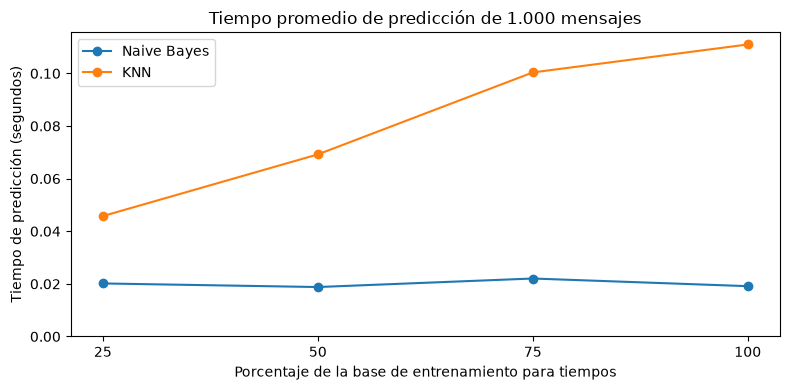

In [14]:
from sklearn.base import clone
from time import perf_counter

# El lote fijo pertenece a entrenamiento y queda fuera del ajuste de este experimento.
textos_base_tiempos, textos_lote_tiempos, etiquetas_base_tiempos, etiquetas_lote_tiempos = train_test_split(
    textos_entrenamiento, etiquetas_entrenamiento,
    test_size=1000, stratify=etiquetas_entrenamiento, random_state=SEMILLA,
)
assert textos_base_tiempos.index.intersection(textos_lote_tiempos.index).empty
assert textos_lote_tiempos.index.intersection(textos_prueba.index).empty
assert len(textos_lote_tiempos) == 1000
display(pd.Series({"Base de entrenamiento para tiempos": len(textos_base_tiempos),
                   "Lote fijo de predicción": len(textos_lote_tiempos)}, name="Mensajes").to_frame())

porcentajes_tiempos = [25, 50, 75, 100]
repeticiones_tiempos = 3
mediciones_tiempos = []
subconjuntos_tiempos = {}
for porcentaje in porcentajes_tiempos:
    cantidad = round(len(textos_base_tiempos) * porcentaje / 100)
    if porcentaje == 100:
        textos_subconjunto, etiquetas_subconjunto = textos_base_tiempos, etiquetas_base_tiempos
    else:
        textos_subconjunto, _, etiquetas_subconjunto, _ = train_test_split(
            textos_base_tiempos, etiquetas_base_tiempos,
            train_size=cantidad, stratify=etiquetas_base_tiempos, random_state=SEMILLA,
        )
    assert textos_subconjunto.index.intersection(textos_lote_tiempos.index).empty
    assert textos_subconjunto.index.intersection(textos_prueba.index).empty
    subconjuntos_tiempos[porcentaje] = textos_subconjunto.index
    modelos_tiempos = {
        "Naive Bayes": clone(modelo_nb_ajustado).fit(textos_subconjunto, etiquetas_subconjunto),
        "KNN": clone(modelo_knn_ajustado).fit(textos_subconjunto, etiquetas_subconjunto),
    }
    # Una llamada previa evita incluir el costo de la primera predicción en el promedio.
    for modelo in modelos_tiempos.values():
        modelo.predict(textos_lote_tiempos)
    for repeticion in range(repeticiones_tiempos):
        for nombre, modelo in modelos_tiempos.items():
            inicio = perf_counter()
            modelo.predict(textos_lote_tiempos)
            segundos = perf_counter() - inicio
            mediciones_tiempos.append({"Entrenamiento (%)": porcentaje, "Mensajes de entrenamiento": cantidad,
                                      "Modelo": nombre, "Repetición": repeticion + 1, "Segundos": segundos})

mediciones_tiempos = pd.DataFrame(mediciones_tiempos)
tabla_tiempos = (
    mediciones_tiempos.groupby(["Entrenamiento (%)", "Mensajes de entrenamiento", "Modelo"])["Segundos"]
    .mean().unstack("Modelo").reset_index()
    .rename(columns={"Naive Bayes": "Naive Bayes (s)", "KNN": "KNN (s)"})
    [["Entrenamiento (%)", "Mensajes de entrenamiento", "Naive Bayes (s)", "KNN (s)"]]
)
tabla_tiempos.columns.name = None
display(tabla_tiempos.round(6))

fig, ax = plt.subplots(figsize=(8, 4))
for nombre, columna in [("Naive Bayes", "Naive Bayes (s)"), ("KNN", "KNN (s)")]:
    ax.plot(tabla_tiempos["Entrenamiento (%)"], tabla_tiempos[columna], marker="o", label=nombre)
ax.set_title("Tiempo promedio de predicción de 1.000 mensajes")
ax.set_xlabel("Porcentaje de la base de entrenamiento para tiempos")
ax.set_ylabel("Tiempo de predicción (segundos)")
ax.set_xticks(porcentajes_tiempos)
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
plt.show()

El 100% corresponde a la base que queda después de reservar el lote de 1.000 mensajes, no a todos los históricos. Ambos modelos usan los mismos subconjuntos estratificados y las configuraciones seleccionadas por validación. Cada promedio incluye tres predicciones completas del pipeline, con transformación del texto y clasificación; excluye entrenamiento y búsqueda de parámetros. Los tiempos pueden variar entre ejecuciones y no representan una medición de producción.

Naive Bayes predijo más rápido en los cuatro tamaños y su tiempo se mantuvo aproximadamente estable. El tiempo de KNN creció al aumentar el entrenamiento porque compara cada consulta con más mensajes almacenados; Naive Bayes usa las probabilidades ya resumidas por clase y término. Para un volumen de 6.500 mensajes diarios, un menor costo de predicción deja más margen de procesamiento, aunque todavía faltan las mediciones y los criterios de un sistema real. Los tiempos favorecen a Naive Bayes en costo, pero por sí solos no justifican la elección final: también hay que considerar la calidad de la clasificación y el tratamiento de fraude.

## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [ ]:
# Tu código aquí

**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

In [ ]:
# Tu código aquí

**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

In [ ]:
# Tu código aquí

**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [ ]:
# Tu código aquí

**Paso 17.** Impacto en un día de 6.500 mensajes.

In [ ]:
# Tu código aquí

## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [ ]:
# Tu código aquí

**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [ ]:
# Tu código aquí

## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. Naive Bayes supone que las palabras son independientes dada la clase. ¿Por qué clasifica bien igual? ¿Qué consecuencia tiene esa suposición sobre las probabilidades?**

_Respuesta:_ 

**2. ¿Qué pasaría con `alpha=0` si aparece una palabra que nunca se vio en la clase `fraude`?**

_Respuesta:_ 

**3. ¿Por qué `equipo_derivado` no puede usarse como variable del modelo?**

_Respuesta:_ 

**4. ¿Qué costo tendría KNN en producción comparado con Naive Bayes? ¿En qué situación elegirían KNN igual?**

_Respuesta:_ 

**5. ¿Quién debería fijar el máximo de fraude perdido y la exactitud mínima? ¿Qué información tiene que llevar el equipo de datos?**

_Respuesta:_ 

**6. Si Cauce lanza un seguro para celulares, ¿qué le pasa al modelo y cómo lo detectarían en producción?**

_Respuesta:_ 

**7. ¿Qué datos personales anonimizarían antes de guardar los datos de entrenamiento y cómo afectaría al modelo?**

_Respuesta:_ 